In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
dataset = pd.read_csv("bank-full.csv", sep=";")

print("Dataset loaded successfully.")

print("Dataset shape:", dataset.shape)

dataset.head()

Dataset loaded successfully.
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
print("Dataset Information:")
dataset.info()

print("\nMissing Values:")
print(dataset.isnull().sum())

print("\nTarget Distribution:")
print(dataset["y"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housi

In [4]:
# Separate input features and target variable
X = dataset.drop("y", axis=1)
y = dataset["y"].map({"no": 0, "yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (45211, 16)
Target shape: (45211,)

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [5]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [6]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 36168
Testing samples: 9043

Training target distribution:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [7]:
# Preprocessing for numerical and categorical features
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [8]:
# Define the five classification model

model = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    )
}

print("Five classification model defined successfully.")

Five classification model defined successfully.


In [9]:
# Train all five classification model

trained_models = {}

for model_name, classifier in model.items():

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("classifier", classifier)
        ]
    )

    model_pipeline.fit(X_train, y_train)

    trained_models[model_name] = model_pipeline

    print(f"{model_name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
K-Nearest Neighbors trained successfully.
Naive Bayes trained successfully.


/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
print("Number of trained model:", len(trained_models))

for model_name in trained_models:
    print(model_name)

Number of trained model: 5
Logistic Regression
Decision Tree
K-Nearest Neighbors
Naive Bayes
Support Vector Machine


In [ ]:
# Evaluate all trained classification model

evaluation_results = []

for model_name, model_pipeline in trained_models.items():

    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    results = {
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    evaluation_results.append(results)

    print(f"{model_name} evaluated successfully.")

Logistic Regression evaluated successfully.
Decision Tree evaluated successfully.
K-Nearest Neighbors evaluated successfully.
Naive Bayes evaluated successfully.
Support Vector Machine evaluated successfully.


In [ ]:
# Create the model comparison table

comparison_df = pd.DataFrame(evaluation_results)

comparison_df = comparison_df.round(4)

comparison_df

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261
1,Decision Tree,0.8746,0.7015,0.4649,0.4754,0.4701,0.3990
2,K-Nearest Neighbors,0.8962,0.8277,0.5990,0.3403,0.4340,0.4001
3,Naive Bayes,0.8548,0.8101,0.4059,0.5198,0.4559,0.3774
4,Support Vector Machine,0.9049,0.9037,0.6875,0.3431,0.4578,0.4420


In [ ]:
# Identify the best model based on F1 Score

best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]

print("Best Model:", best_model["ML Model Name"])
print("F1 Score:", best_model["F1 Score"])
print("AUC Score:", best_model["AUC"])

Best Model: Decision Tree
F1 Score: 0.4701
AUC Score: 0.7015


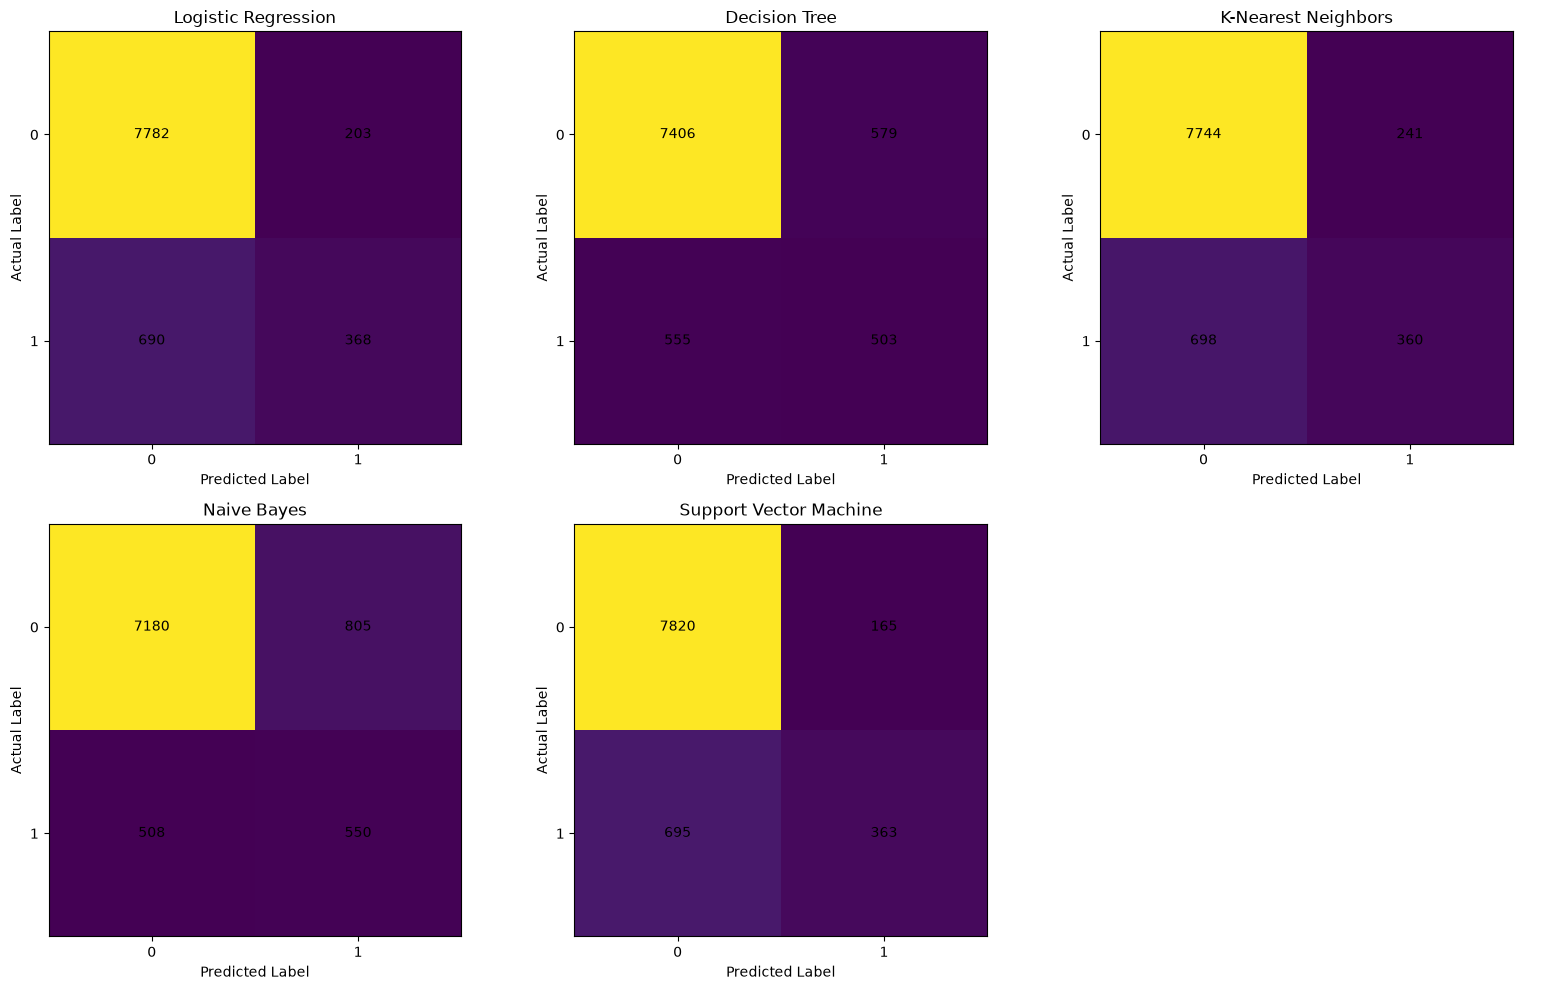

In [ ]:
# Display confusion matrices for all five model

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for index, (model_name, model_pipeline) in enumerate(trained_models.items()):

    y_pred = model_pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    axes[index].imshow(cm)

    axes[index].set_title(model_name)
    axes[index].set_xlabel("Predicted Label")
    axes[index].set_ylabel("Actual Label")

    axes[index].set_xticks([0, 1])
    axes[index].set_yticks([0, 1])

    for i in range(2):
        for j in range(2):
            axes[index].text(
                j, i, cm[i, j],
                ha="center",
                va="center"
            )

axes[5].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Generate detailed classification reports

for model_name, model_pipeline in trained_models.items():

    y_pred = model_pipeline.predict(X_test)

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Subscription", "Subscription"],
            zero_division=0
        )
    )


Logistic Regression
                 precision    recall  f1-score   support

No Subscription       0.92      0.97      0.95      7985
   Subscription       0.64      0.35      0.45      1058

       accuracy                           0.90      9043
      macro avg       0.78      0.66      0.70      9043
   weighted avg       0.89      0.90      0.89      9043


Decision Tree
                 precision    recall  f1-score   support

No Subscription       0.93      0.93      0.93      7985
   Subscription       0.46      0.48      0.47      1058

       accuracy                           0.87      9043
      macro avg       0.70      0.70      0.70      9043
   weighted avg       0.88      0.87      0.88      9043


K-Nearest Neighbors
                 precision    recall  f1-score   support

No Subscription       0.92      0.97      0.94      7985
   Subscription       0.60      0.34      0.43      1058

       accuracy                           0.90      9043
      macro avg       0

In [ ]:
import os
import joblib

# Create a folder to store the trained model
os.makedirs("model", exist_ok=True)

# Save each trained model
for model_name, model_pipeline in trained_models.items():

    file_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )

    file_path = os.path.join("model", file_name)

    joblib.dump(model_pipeline, file_path)

    print(f"Saved: {file_path}")

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/k_nearest_neighbors.joblib
Saved: model/naive_bayes.joblib
Saved: model/support_vector_machine.joblib


In [ ]:
# Combine test features and target into one dataset

test_dataset = X_test.copy()

test_dataset["y"] = y_test.map({
    0: "no",
    1: "yes"
})

# Save the test dataset
test_dataset.to_csv("test_data.csv", index=False)

print("Test dataset exported successfully.")
print("Test data shape:", test_dataset.shape)

Test dataset exported successfully.
Test data shape: (9043, 17)


In [12]:
from pathlib import Path
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

project_dir = Path.cwd()

test_data = pd.read_csv(project_dir / "test_data.csv")
X_test = test_data.drop(columns=["y"])
y_test = test_data["y"].map({"no": 0, "yes": 1})

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "k_nearest_neighbors.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

results = []

for model_name, filename in model_files.items():
    model = joblib.load(project_dir / "model" / filename)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

comparison_df = pd.DataFrame(results).round(4)
comparison_df

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261
1,Decision Tree,0.8746,0.7015,0.4649,0.4754,0.4701,0.3990
2,K-Nearest Neighbors,0.8962,0.8277,0.5990,0.3403,0.4340,0.4001
3,Naive Bayes,0.8548,0.8101,0.4059,0.5198,0.4559,0.3774
4,Support Vector Machine,0.9049,0.9037,0.6875,0.3431,0.4578,0.4420
